In [1]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone

from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    precision_recall_curve, 
    average_precision_score
)

## <b>Global Variables.</b>

In [2]:
# Paths for BTCUSDT.
PATH_BINANCE_PERP_BTCUSDT_LOB       = r'data\binance_booktickers\perp_btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_LIQUID    = r'data\binance_liquidations\perp_btcusdt.parquet'
PATH_BYBIT_PERP_BTCUSDT_LIQUID      = r'data\bybit_liquidations\btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_TRADES    = r'data\binance_trades\perp_btcusdt.parquet'

# Paths for ETHUSDT.
PATH_BINANCE_PERP_ETHUSDT_LOB       = r'data\binance_booktickers\perp_ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_LIQUID    = r'data\binance_liquidations\perp_ethusdt.parquet'
PATH_BYBIT_PERP_ETHUSDT_LIQUID      = r'data\bybit_liquidations\ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_TRADES    = r'data\binance_trades\perp_ethusdt.parquet'

# All .parquet files.
PARQUET_FILES = {
    "binance_perp_btcusdt_lob": PATH_BINANCE_PERP_BTCUSDT_LOB,
    "binance_perp_btcusdt_liquid": PATH_BINANCE_PERP_BTCUSDT_LIQUID,
    "bybit_perp_btcusdt_liquid": PATH_BYBIT_PERP_BTCUSDT_LIQUID,
    "binance_perp_btcusdt_trades": PATH_BINANCE_PERP_BTCUSDT_TRADES,

    "binance_perp_ethusdt_lob": PATH_BINANCE_PERP_ETHUSDT_LOB,
    "binance_perp_ethusdt_liquid": PATH_BINANCE_PERP_ETHUSDT_LIQUID,
    "bybit_perp_ethusdt_liquid": PATH_BYBIT_PERP_ETHUSDT_LIQUID,
    "binance_perp_ethusdt_trades": PATH_BINANCE_PERP_ETHUSDT_TRADES,
}

In [3]:
# parse the data.
lf_btc_trades       = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_TRADES)
lf_btc_lob          = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_LOB)
lf_btc_liq_binance  = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_LIQUID)
lf_btc_liq_bybit    = pl.scan_parquet(PATH_BYBIT_PERP_BTCUSDT_LIQUID)

lf_eth_trades       = pl.scan_parquet(PATH_BINANCE_PERP_ETHUSDT_TRADES)
lf_eth_lob          = pl.scan_parquet(PATH_BINANCE_PERP_ETHUSDT_LOB)
lf_eth_liq_binance  = pl.scan_parquet(PATH_BINANCE_PERP_ETHUSDT_LIQUID)
lf_eth_liq_bybit    = pl.scan_parquet(PATH_BYBIT_PERP_ETHUSDT_LIQUID)

## <b>1. Liquidation heatmap.</b>

The goal of this section is to visualize liquidation in both time and price space.

A liquidation heatmap aggregates liquidation dollar volume by:
- time bucket;
- price bucket.

The x-axis represents time, the y-axis represents price levels, and the color intensity represents:

$\log(1 + \text{liquidation volume in USD}).$

The logarithmic scale is used because liquidation volumes are highly skewed.

I also overlay the average mid-price to compare liquidation clusters with the realized price path.

The main hypothesis is that liquidations are not uniformly distributed. They should cluster around sharp price moves and stress periods.

In [4]:
def liquidation_heatmap_day_price(
    lf_liq_binance: pl.LazyFrame,
    lf_liq_bybit: pl.LazyFrame,
    lf_lob: pl.LazyFrame,
    name: str,
    price_bin_size: float,
):
    """
    Builds liquidation heatmap:
    x-axis: day,
    y-axis: price bin,
    color: log(1 + liquidation dollar volume).

    Binance and Bybit liquidations are aggregated together.
    Average daily mid-price is overlaid.
    """


    # Prepare liquidation data.
    def prepare_liq(lf: pl.LazyFrame, exchange: str) -> pl.LazyFrame:
        if exchange == "bybit":
            lf = lf.with_columns(
                (pl.col("timestamp") + 200_000).alias("timestamp")
            )

        return (
            lf
            .select(
                (pl.col("timestamp") // 86_400_000_000).alias("day"),
                pl.col("price"),
                (pl.col("price") * pl.col("amount")).alias("dollar_amount"),
                pl.col("side"),
                pl.lit(exchange).alias("exchange"),
            )
            .with_columns(
                (pl.col("price") / price_bin_size)
                .floor()
                .cast(pl.Int64)
                .alias("price_bin")
            )
            .select(
                "day",
                "price_bin",
                "dollar_amount",
                "side",
                "exchange",
            )
        )

    df_heatmap = (
        pl.concat(
            [
                prepare_liq(lf_liq_binance, "binance"),
                prepare_liq(lf_liq_bybit, "bybit"),
            ]
        )
        .group_by(["day", "price_bin"])
        .agg(
            pl.col("dollar_amount").sum().alias("volume")
        )
        .sort(["day", "price_bin"])
        .collect(engine="streaming")
    )


    # Daily average mid-price.
    df_mid = (
        lf_lob
        .select(
            (pl.col("timestamp") // 86_400_000_000).alias("day"),
            ((pl.col("bid_price") + pl.col("ask_price")) / 2).alias("mid"),
        )
        .group_by("day")
        .agg(
            pl.col("mid").mean().alias("mid_avg")
        )
        .sort("day")
        .collect(engine="streaming")
    )


    # Build full day and price-bin ranges.
    liq_days = set(df_heatmap["day"].to_list())
    mid_days = set(df_mid["day"].to_list())
    days = sorted(liq_days | mid_days)

    day_idx = {
        day: idx
        for idx, day in enumerate(days)
    }

    liq_min_bin = df_heatmap["price_bin"].min()
    liq_max_bin = df_heatmap["price_bin"].max()

    mid_min_bin = int(np.floor(df_mid["mid_avg"].min() / price_bin_size))
    mid_max_bin = int(np.floor(df_mid["mid_avg"].max() / price_bin_size))

    min_bin = min(liq_min_bin, mid_min_bin)
    max_bin = max(liq_max_bin, mid_max_bin)

    bins = list(range(min_bin, max_bin + 1))

    bin_idx = {
        price_bin: idx
        for idx, price_bin in enumerate(bins)
    }


    # build heatmap matrix.
    matrix = np.zeros(
        shape=(len(bins), len(days)),
        dtype=float,
    )

    for row in df_heatmap.iter_rows(named=True):
        day = row["day"]
        price_bin = row["price_bin"]
        volume = row["volume"]

        if day in day_idx and price_bin in bin_idx:
            x = day_idx[day]
            y = bin_idx[price_bin]
            matrix[y, x] = volume


    # mid-price overlay coordinates.
    mid_x = []
    mid_y = []

    for row in df_mid.iter_rows(named=True):
        day = row["day"]
        mid = row["mid_avg"]

        if day not in day_idx:
            continue

        mid_x.append(day_idx[day])
        mid_y.append((mid / price_bin_size) - min_bin)



    # axis labels.
    day_labels = [ datetime.fromtimestamp(day * 86400, tz=timezone.utc).strftime("%m-%d") for day in days]
    price_labels = [ f"${int(price_bin * price_bin_size):,}" for price_bin in bins]


    # plot.
    fig, ax = plt.subplots(figsize=(16, 8))

    im = ax.imshow(
        np.log1p(matrix),
        aspect="auto",
        origin="lower",
        interpolation="nearest",
        cmap="YlOrRd",
    )

    fig.colorbar(
        im,
        ax=ax,
        label="log(1 + liquidation volume USD)",
    )

    ax.plot(
        mid_x,
        mid_y,
        color="cyan",
        linewidth=2,
        label="Average mid price",
    )

    ax.legend(loc="upper right")

    tick_step_x = max(1, len(days) // 15)
    tick_step_y = max(1, len(bins) // 15)

    x_ticks = list(range(0, len(days), tick_step_x))
    y_ticks = list(range(0, len(bins), tick_step_y))

    ax.set_xticks(x_ticks)
    ax.set_xticklabels(
        [day_labels[i] for i in x_ticks],
        rotation=45,
        fontsize=8,
    )

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(
        [price_labels[i] for i in y_ticks],
        fontsize=8,
    )

    ax.set_title(f"{name} - Liquidation Heatmap (day × price)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Price level")

    plt.tight_layout()
    plt.show()

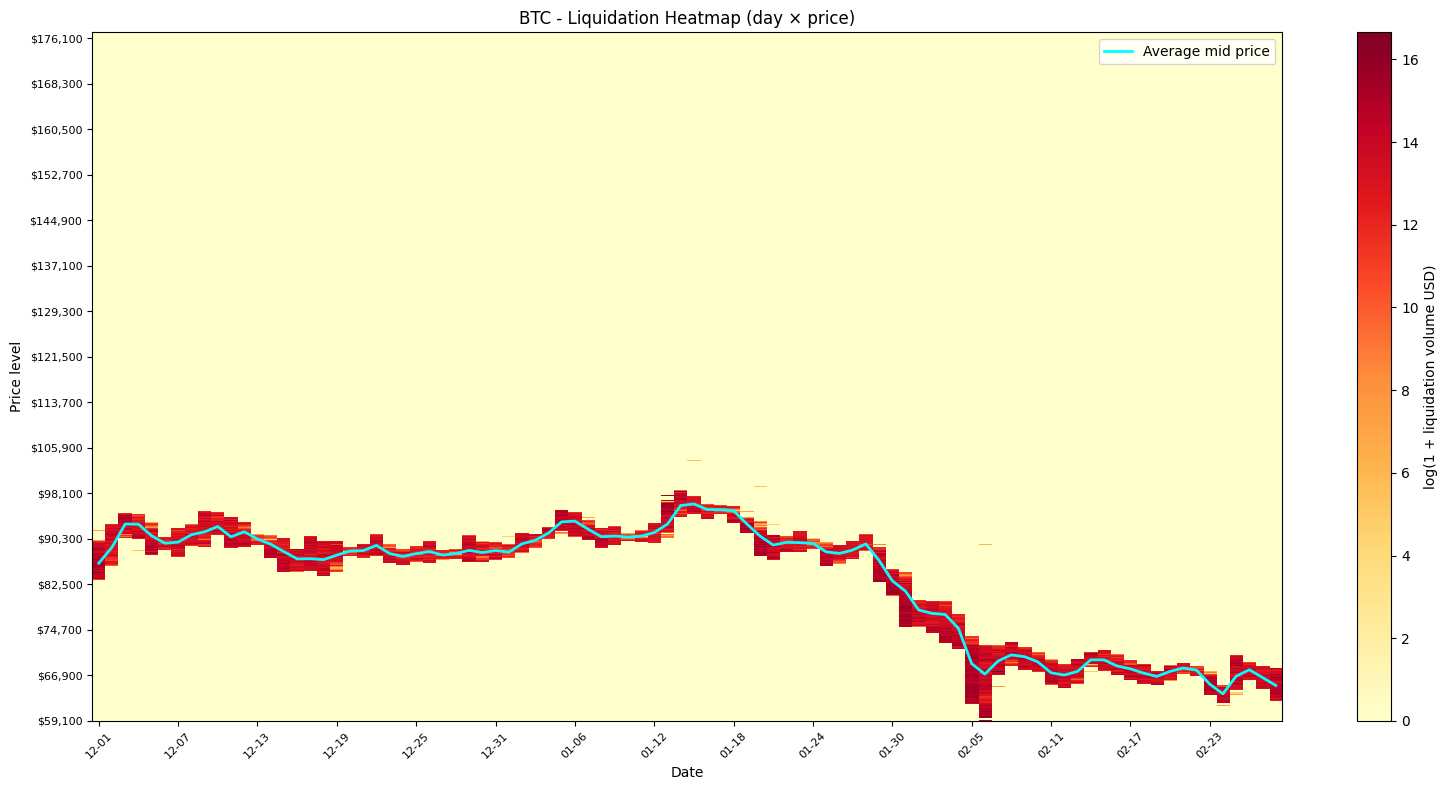

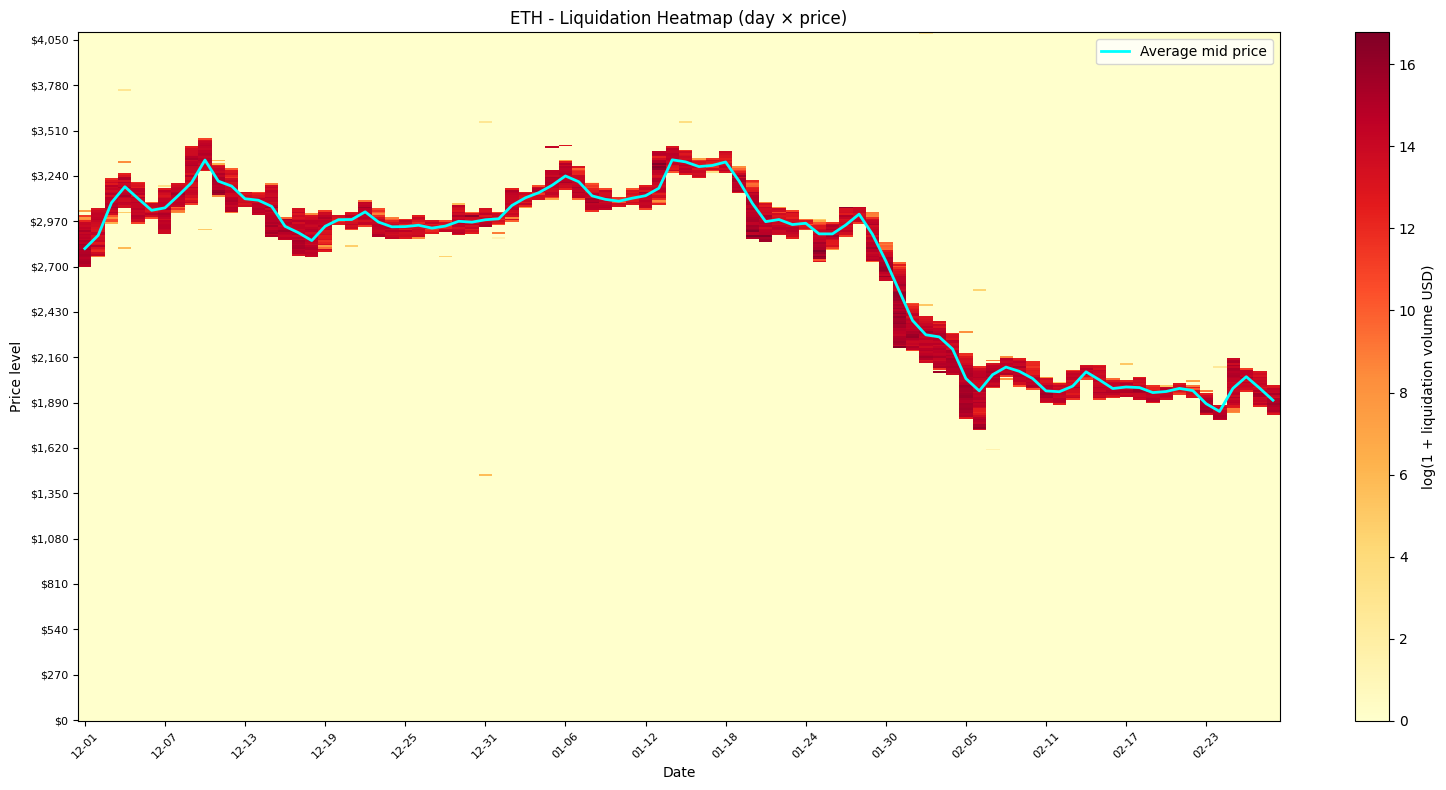

In [5]:
liquidation_heatmap_day_price(
    lf_liq_binance  = lf_btc_liq_binance,
    lf_liq_bybit    = lf_btc_liq_bybit,
    lf_lob          = lf_btc_lob,
    name            = "BTC",
    price_bin_size  = 100
)

liquidation_heatmap_day_price(
    lf_liq_binance  = lf_eth_liq_binance,
    lf_liq_bybit    = lf_eth_liq_bybit,
    lf_lob          = lf_eth_lob,
    name            = "ETH",
    price_bin_size  = 10,
)

## <b>Heatmap Interpretation.</b>

The heatmap shows that liquidation activity is highly clustered in both time and price space.

Liquidations are not spread uniformly across the sample. This is consistent with the liquidation cascade mechanism.

## <b>2. Simple ML baseline for future liquidation stress.</b>

The goal of this section is to test whether the features constructed from market activity, liquidity, and liquidation flow contain predictive information about future liquidation stress.

I formulate two simple prediction problems.

First, we use a regression model to predict future liquidation volume over the next \(h\) minutes:

$y_t = \log(1 + L_{t:t+h}),$

where

$L_{t:t+h} = \sum_{j=1}^{h} L_{t+j}.$

Second, we use a classification model to predict whether a large liquidation event will occur in the next \(h\) minutes:

$y_t =\mathbf{1}\left\{L_{t:t+h} > Q_{0.95}^{train}\right\}.$

The threshold \(Q_{0.95}^{train}\) is computed only on the training period to avoid look-ahead bias.

The feature set includes:
- recent volatility.
- trading volume.
- LOB spread-based liquidity.
- recent liquidation volume.
- liquidation imbalance.
- Amihud illiquidity (Lopez De Prado: Advances in Financial ML(19.4.2)).

The train/test split is chronological, without shuffling(else look-ahead bias).

The goal is to check whether the EDA features can identify future market stress regimes.

### <b>2.1. Functions.</b>

In [6]:
def build_ml_liquidation_table(
    lf_trades: pl.LazyFrame,
    lf_lob: pl.LazyFrame,
    lf_liq_binance: pl.LazyFrame,
    lf_liq_bybit: pl.LazyFrame,
    horizon: int = 15,
) -> pl.DataFrame:
    """
    Builds minute-level ML table directly from LazyFrames.

    Features use only information available at current or past minutes.
    Target uses future liquidation volume over the next horizon minutes.
    """

    # Trades.
    lf_trades_min = (
        lf_trades
        .select(
            (pl.col("timestamp") // 60_000_000).alias("minute"),
            (pl.col("price") * pl.col("amount")).alias("dollar_amount"),
            pl.col("side"),
        )
        .group_by("minute")
        .agg(
            pl.col("dollar_amount").sum().alias("trade_volume"),
            pl.len().alias("trade_count"),

            pl.col("dollar_amount")
            .filter(pl.col("side") == "buy")
            .sum()
            .alias("buy_volume"),

            pl.col("dollar_amount")
            .filter(pl.col("side") == "sell")
            .sum()
            .alias("sell_volume"),
        )
        .with_columns(
            pl.col("buy_volume").fill_null(0),
            pl.col("sell_volume").fill_null(0),
        )
        .with_columns(
            (
                (pl.col("buy_volume") - pl.col("sell_volume"))
                / (pl.col("buy_volume") + pl.col("sell_volume"))
            ).alias("trade_imbalance")
        )
        .sort("minute")
    )


    # LOB.
    lf_lob_min = (
        lf_lob
        .select(
            (pl.col("timestamp") // 60_000_000).alias("minute"),
            pl.col("bid_price"),
            pl.col("ask_price"),
        )
        .with_columns(
            ((pl.col("bid_price") + pl.col("ask_price")) / 2).alias("mid"),
            (pl.col("ask_price") - pl.col("bid_price")).alias("spread"),
            (
                (pl.col("ask_price") - pl.col("bid_price"))
                / (2 * ((pl.col("bid_price") + pl.col("ask_price")) / 2))
                * 10_000
            ).alias("half_spread_bps_raw"),
        )
        .group_by("minute")
        .agg(
            pl.col("mid").last().alias("mid_close"),
            pl.col("mid").std().alias("mid_intraminute_std"),
            pl.col("spread").mean().alias("avg_spread"),
            pl.col("half_spread_bps_raw").mean().alias("half_spread_bps"),
            pl.len().alias("lob_updates"),
        )
        .sort("minute")
    )


    # Liquidations.
    def prepare_liq(lf: pl.LazyFrame, exchange: str) -> pl.LazyFrame:
        if exchange == "bybit":
            lf = lf.with_columns(
                (pl.col("timestamp") + 200_000).alias("timestamp")
            )

        return (
            lf
            .select(
                (pl.col("timestamp") // 60_000_000).alias("minute"),
                (pl.col("price") * pl.col("amount")).alias("liq_dollar_amount"),
                pl.col("side"),
                pl.lit(exchange).alias("exchange"),
            )
        )

    lf_liq_min = (
        pl.concat(
            [
                prepare_liq(lf_liq_binance, "binance"),
                prepare_liq(lf_liq_bybit, "bybit"),
            ]
        )
        .group_by("minute")
        .agg(
            pl.col("liq_dollar_amount").sum().alias("liq_total_volume"),
            pl.len().alias("liq_event_count"),

            pl.col("liq_dollar_amount")
            .filter(pl.col("side") == "buy")
            .sum()
            .alias("liq_buy_volume"),

            pl.col("liq_dollar_amount")
            .filter(pl.col("side") == "sell")
            .sum()
            .alias("liq_sell_volume"),
        )
        .with_columns(
            pl.col("liq_buy_volume").fill_null(0),
            pl.col("liq_sell_volume").fill_null(0),
        )
        .with_columns(
            (pl.col("liq_buy_volume") - pl.col("liq_sell_volume")).alias("liq_net_volume"),
            (
                (pl.col("liq_buy_volume") - pl.col("liq_sell_volume"))
                / (pl.col("liq_buy_volume") + pl.col("liq_sell_volume"))
            ).alias("liq_imbalance"),
        )
        .sort("minute")
    )


    # Join all.
    df = (
        lf_lob_min
        .join(lf_trades_min, on="minute", how="left")
        .join(lf_liq_min, on="minute", how="left")
        .sort("minute")
        .collect(engine="streaming")
    )


    # Fill missing activity with zeros.
    zero_cols = [
        "trade_volume",
        "trade_count",
        "buy_volume",
        "sell_volume",
        "trade_imbalance",
        "liq_total_volume",
        "liq_event_count",
        "liq_buy_volume",
        "liq_sell_volume",
        "liq_net_volume",
        "liq_imbalance",
    ]

    df = df.with_columns(
        [
            pl.col(col).fill_null(0)
            for col in zero_cols
            if col in df.columns
        ]
    )


    # Returns and transforms.
    df = (
        df
        .with_columns(
            pl.col("mid_close").log().diff().alias("return_1m"),
        )
        .with_columns(
            pl.col("return_1m").abs().alias("abs_return_1m"),
            np.log1p(pl.col("trade_volume")).alias("log_trade_volume"),
            np.log1p(pl.col("liq_total_volume")).alias("log_liq_total_volume"),
        )
        .with_columns(
            (
                pl.col("abs_return_1m")
                / (pl.col("trade_volume"))
            ).alias("amihud_1m")
        )
        .with_columns(
            (pl.col("amihud_1m") * 1_000_000).alias("amihud_per_1m_usd")
        )
    )


    # Rolling causal features.
    df = (
        df
        .with_columns(
            # Volatility.
            pl.col("abs_return_1m").rolling_mean(window_size=15).alias("abs_return_mean_15m"),
            pl.col("abs_return_1m").rolling_mean(window_size=60).alias("abs_return_mean_60m"),
            (pl.col("return_1m") ** 2).rolling_sum(window_size=60).alias("rv_60m"),

            # Trade volume.
            pl.col("trade_volume").rolling_sum(window_size=60).alias("trade_volume_sum_60m"),

            # BBO liquidity.
            pl.col("half_spread_bps").rolling_mean(window_size=30).alias("half_spread_mean_30m"),
            pl.col("half_spread_bps").rolling_mean(window_size=60).alias("half_spread_mean_60m"),
            pl.col("half_spread_bps").rolling_std(window_size=60).alias("half_spread_std_60m"),

            # Liquidations.
            pl.col("liq_total_volume").rolling_sum(window_size=15).alias("liq_total_sum_15m"),
            pl.col("liq_total_volume").rolling_sum(window_size=60).alias("liq_total_sum_60m"),
            pl.col("liq_buy_volume").rolling_sum(window_size=60).alias("liq_buy_sum_60m"),
            pl.col("liq_sell_volume").rolling_sum(window_size=60).alias("liq_sell_sum_60m"),

            # Amihud.
            pl.col("amihud_1m").rolling_median(window_size=60).alias("amihud_median_60m"),
        )
        .with_columns(
            (
                (pl.col("half_spread_bps") - pl.col("half_spread_mean_60m"))
                / (pl.col("half_spread_std_60m"))
            ).alias("half_spread_zscore_60m"),

            (
                (pl.col("liq_total_volume") - pl.col("liq_total_volume").rolling_mean(window_size=60))
                / (pl.col("liq_total_volume").rolling_std(window_size=60))
            ).alias("liq_zscore_60m"),

            (
                (pl.col("liq_buy_sum_60m") - pl.col("liq_sell_sum_60m"))
                / (pl.col("liq_buy_sum_60m") + pl.col("liq_sell_sum_60m"))
            ).alias("liq_imbalance_60m"),
        )
    )


    # future target.
    future_col = f"future_liq_volume_{horizon}m"
    log_future_col = f"log_future_liq_volume_{horizon}m"

    df = (
        df
        .with_columns(
            (
                pl.col("liq_total_volume")
                .reverse()
                .rolling_sum(window_size=horizon)
                .reverse()
                .shift(-1)
            ).alias(future_col)
        )
        .with_columns(
            pl.when(pl.col(future_col) < 0)
            .then(0.0)
            .otherwise(pl.col(future_col))
            .alias(future_col)
        )
        .with_columns(
            np.log1p(pl.col(future_col)).alias(log_future_col)
        )
    )


    # datetime.
    df = df.with_columns(
        (pl.col("minute") * 60 * 1000)
        .cast(pl.Datetime("ms"))
        .alias("datetime")
    )

    return df

In [ ]:
feature_cols = [
    # Volatility.
    "abs_return_1m",
    "abs_return_mean_15m",
    "abs_return_mean_60m",
    "rv_60m",

    # Trading activity.
    "trade_volume",
    "log_trade_volume",
    "trade_volume_sum_60m",
    "trade_imbalance",

    # LOB liquidity proxy.
    "half_spread_bps",
    "half_spread_mean_30m",
    "half_spread_mean_60m",
    "half_spread_zscore_60m",

    # Liquidation pressure.
    "liq_total_volume",
    "log_liq_total_volume",
    "liq_total_sum_15m",
    "liq_total_sum_60m",
    "liq_imbalance",
    "liq_imbalance_60m",
    "liq_zscore_60m",

    # Illiquidity.
    "amihud_per_1m_usd",
    "amihud_median_60m",
]

In [8]:
def prepare_ml_dataset(
    df: pl.DataFrame,
    feature_cols: list[str],
    target_col: str,
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Prepares ML matrix X and target y.
    """

    available_features = [
        col for col in feature_cols
        if col in df.columns
    ]

    needed_cols = available_features + [target_col]

    data = (
        df
        .select(needed_cols)
        .drop_nulls()
        .filter(
            pl.all_horizontal([
                pl.col(col).is_finite()
                for col in needed_cols
            ])
        )
    )

    pdf = data.to_pandas()

    X = pdf[available_features]
    y = pdf[target_col]

    return X, y

In [9]:
def time_train_test_split(
    X: pd.DataFrame,
    y: pd.Series,
    train_frac: float = 0.70,
):
    """
    Chronological right train/test split.
    """

    n = len(X)
    split = int(n * train_frac)

    X_train = X.iloc[:split].copy()
    X_test = X.iloc[split:].copy()

    y_train = y.iloc[:split].copy()
    y_test = y.iloc[split:].copy()

    return X_train, X_test, y_train, y_test

In [10]:
df_btc_ml = build_ml_liquidation_table(
    lf_trades       = lf_btc_trades,
    lf_lob          = lf_btc_lob,
    lf_liq_binance  = lf_btc_liq_binance,
    lf_liq_bybit    = lf_btc_liq_bybit,
    horizon         = 5
)

df_eth_ml = build_ml_liquidation_table(
    lf_trades       = lf_eth_trades,
    lf_lob          = lf_eth_lob,
    lf_liq_binance  = lf_eth_liq_binance,
    lf_liq_bybit    = lf_eth_liq_bybit,
    horizon         = 5
)

In [25]:
def train_future_liq_regression(
    df: pl.DataFrame,
    asset_name: str,
    horizon: int = 15,
):
    """
    Regression model for log future liquidation volume.
    """

    target_col = f"log_future_liq_volume_{horizon}m"

    X, y = prepare_ml_dataset(
        df              = df,
        feature_cols    = feature_cols,
        target_col      = target_col,
    )

    X_train, X_test, y_train, y_test = time_train_test_split(X, y, train_frac = 0.70)

    model = XGBRegressor(
        max_depth           = 4,
        learning_rate       = 0.05,
        reg_lambda          = 1.0,
        random_state        = 42,
        subsample           = 0.6,
    )

    model.fit(X_train, y_train)

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    print("=" * 80)
    print(f"{asset_name}: Regression - predict {target_col}")
    print("=" * 80)

    print("Train:")
    print(f"MAE:  {mean_absolute_error(y_train, pred_train):.4f}")
    print(f"R2:   {r2_score(y_train, pred_train):.4f}")

    print("\nTest:")
    print(f"MAE:  {mean_absolute_error(y_test, pred_test):.4f}")
    print(f"R2:   {r2_score(y_test, pred_test):.4f}")

    return model, X_train, X_test, y_train, y_test, pred_test

In [26]:
def plot_regression_predictions(
    y_test: pd.Series,
    pred_test: np.ndarray,
    asset_name: str,
    max_points: int = 3000,
):
    """
    Plots actual vs predicted target values on the test set.
    """

    n = min(len(y_test), max_points)

    _, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        np.arange(n),
        y_test.iloc[:n].values,
        linewidth=1,
        label="Actual",
    )

    ax.plot(
        np.arange(n),
        pred_test[:n],
        linewidth=1,
        label="Predicted",
    )

    ax.set_title(f"{asset_name}: actual vs predicted future liquidation volume")
    ax.set_xlabel("Test time index")
    ax.set_ylabel("log future liquidation volume")
    ax.legend()

    plt.tight_layout()
    plt.show()

In [27]:
def train_future_liq_classifier(
    df: pl.DataFrame,
    asset_name: str,
    horizon: int = 15,
    quantile: float = 0.95,
):
    """
    Classifier for future large liquidation events.
    """

    raw_target_col = f"future_liq_volume_{horizon}m"

    X, y_raw = prepare_ml_dataset(
        df              = df,
        feature_cols    = feature_cols,
        target_col      = raw_target_col,
    )

    X_train, X_test, y_train_raw, y_test_raw = time_train_test_split(X, y_raw, train_frac = 0.70,)

    threshold = y_train_raw.quantile(quantile)

    y_train = (y_train_raw > threshold).astype(int)
    y_test = (y_test_raw > threshold).astype(int)

    model = XGBClassifier(
        max_depth           = 4,
        learning_rate       = 0.05,
        reg_lambda          = 1.0,
        random_state        = 42,
        subsample           = 0.6,
    )

    model.fit(X_train, y_train)

    proba_test = model.predict_proba(X_test)[:, 1]
    pred_test = (proba_test >= 0.5).astype(int)

    print("=" * 80)
    print(f"{asset_name}: Classification - future large liquidation event")
    print("=" * 80)
    print(f"Horizon: {horizon} minutes")
    print(f"Train threshold Q{quantile:.2f}: {threshold:,.2f} USD")
    print(f"Test positive rate: {y_test.mean():.4%}")

    print("\nTest metrics:")
    print(f"ROC-AUC: {roc_auc_score(y_test, proba_test):.4f}")
    print(f"PR-AUC:  {average_precision_score(y_test, proba_test):.4f}")

    print("\nClassification report at threshold 0.5:")
    print(classification_report(y_test, pred_test, digits=4))

    return model, X_train, X_test, y_train, y_test, proba_test, threshold

In [28]:
def threshold_report(
    y_true,
    proba,
    asset_name: str,
):
    """
    Shows precision/recall/F1 for different probability thresholds.
    """

    thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

    rows = []

    for thr in thresholds:
        pred = (proba >= thr).astype(int)

        rows.append(
            {
                "asset": asset_name,
                "threshold": thr,
                "pred_positive_rate": pred.mean(),
                "precision": precision_score(y_true, pred, zero_division=0),
                "recall": recall_score(y_true, pred, zero_division=0),
                "f1": f1_score(y_true, pred, zero_division=0),
            }
        )

    res = pd.DataFrame(rows)
    display(res)

    return res

In [29]:
def plot_precision_recall_curve(
    y_true,
    proba,
    asset_name: str,
    title_suffix: str = "",
):
    """
    Plots Precision-Recall curve for rare-event classification.

    Parameters
    ----------
    y_true:
        True binary labels.

    proba:
        Predicted probabilities for class 1.

    asset_name:
        Asset name, for example "BTC" or "ETH".

    title_suffix:
        Optional text for the plot title.
    """

    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    ap = average_precision_score(y_true, proba)
    base_rate = np.mean(y_true)

    _, ax = plt.subplots(figsize=(7, 5))

    ax.plot(
        recall,
        precision,
        linewidth=2,
        label=f"PR curve, AP={ap:.4f}",
    )

    ax.axhline(
        base_rate,
        linestyle="--",
        linewidth=1,
        label=f"Base rate={base_rate:.4f}",
    )

    ax.set_title(f"{asset_name}: Precision-Recall curve {title_suffix}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend()

    plt.tight_layout()
    plt.show()

### <b>2.2. Train regression.</b>

BTC: Regression - predict log_future_liq_volume_5m
Train:
MAE:  3.6838
R2:   0.2609

Test:
MAE:  3.3842
R2:   0.2489
ETH: Regression - predict log_future_liq_volume_5m
Train:
MAE:  3.4586
R2:   0.2675

Test:
MAE:  3.1049
R2:   0.2446


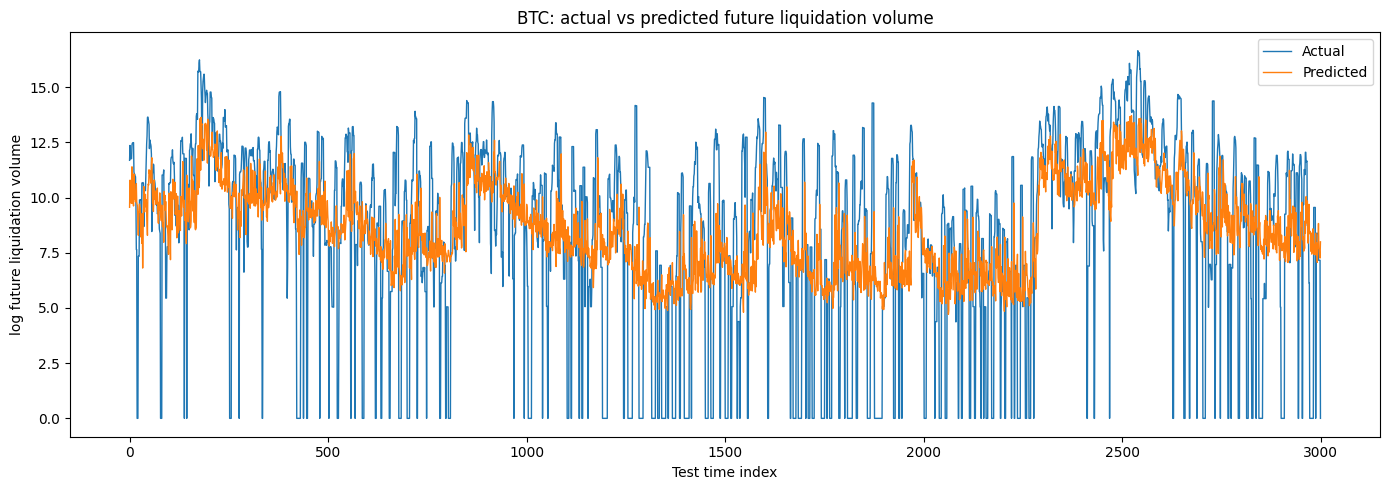

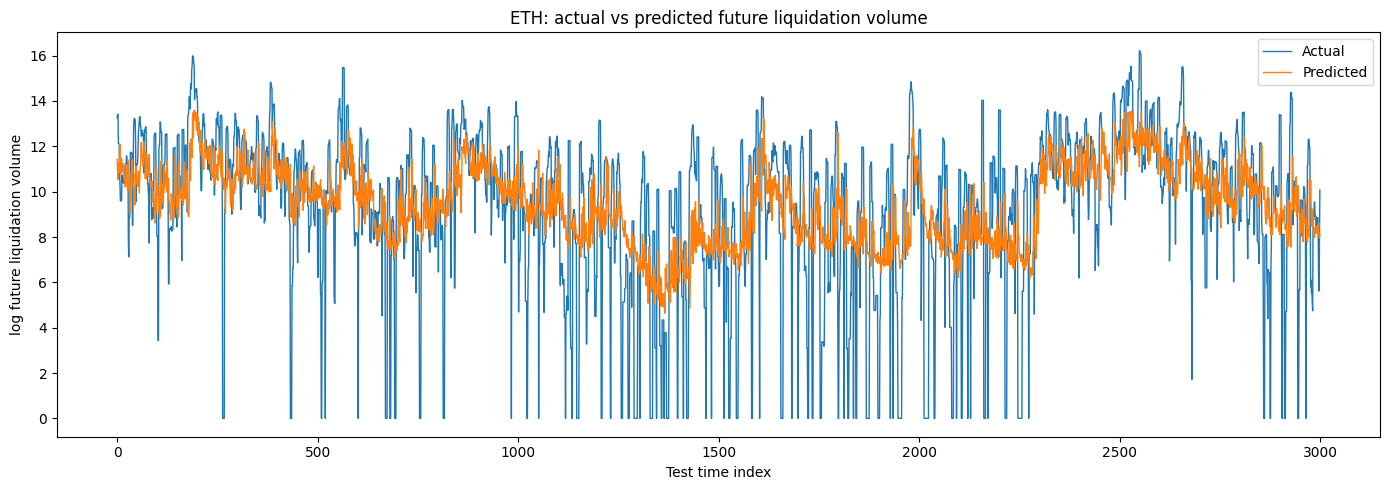

In [30]:
# train regression btc.
reg_btc, X_train_btc, X_test_btc, y_train_btc, y_test_btc, pred_btc = train_future_liq_regression(
    df          = df_btc_ml,
    asset_name  = "BTC",
    horizon     = 5,
)

# train regression eth.
reg_eth, X_train_eth, X_test_eth, y_train_eth, y_test_eth, pred_eth = train_future_liq_regression(
    df          =df_eth_ml,
    asset_name  = "ETH",
    horizon     = 5,
)

# plot predictions.
plot_regression_predictions(y_test_btc, pred_btc, "BTC")
plot_regression_predictions(y_test_eth, pred_eth, "ETH")

### <b>Results: regression.</b>

The regression model predicts the log-transformed future liquidation volume.

The model achieves positive $(R^2)$ on test data, which means that the constructed features explain part of the variation in future liquidation pressure.

The prediction plot shows that the model captures the broad liquidation-stress regime, but it does not predict every local spike. This is expected for  data: liquidation volume is heavy-tailed.

### <b>2.3. Train classification.</b>

BTC: Classification - future large liquidation event
Horizon: 5 minutes
Train threshold Q0.95: 467,250.69 USD
Test positive rate: 8.1390%

Test metrics:
ROC-AUC: 0.8078
PR-AUC:  0.3457

Classification report at threshold 0.5:
              precision    recall  f1-score   support

           0     0.9254    0.9950    0.9589     35688
           1     0.6247    0.0942    0.1638      3162

    accuracy                         0.9217     38850
   macro avg     0.7751    0.5446    0.5613     38850
weighted avg     0.9009    0.9217    0.8942     38850

ETH: Classification - future large liquidation event
Horizon: 5 minutes
Train threshold Q0.95: 404,759.92 USD
Test positive rate: 6.4732%

Test metrics:
ROC-AUC: 0.8072
PR-AUC:  0.2763

Classification report at threshold 0.5:
              precision    recall  f1-score   support

           0     0.9397    0.9953    0.9667     36294
           1     0.5304    0.0764    0.1336      2512

    accuracy                         0.9358     38806
   

,asset,threshold,pred_positive_rate,precision,recall,f1
0,BTC,0.05,0.545714,0.132258,0.886781,0.230185
1,BTC,0.10,0.296963,0.199099,0.726439,0.312538
2,BTC,0.15,0.177014,0.265377,0.577166,0.363582
3,BTC,0.20,0.123192,0.314041,0.475332,0.378208
4,BTC,0.25,0.082059,0.378921,0.382037,0.380472
5,BTC,0.30,0.055573,0.436313,0.297913,0.354069
6,BTC,0.40,0.028571,0.529730,0.185958,0.275281
7,BTC,0.50,0.012278,0.624738,0.094244,0.163781


,asset,threshold,pred_positive_rate,precision,recall,f1
0,ETH,0.05,0.425347,0.127953,0.840764,0.222105
1,ETH,0.10,0.205355,0.193374,0.613455,0.294056
2,ETH,0.15,0.114931,0.256278,0.455016,0.327883
3,ETH,0.20,0.076457,0.299966,0.354299,0.324877
4,ETH,0.25,0.056022,0.339466,0.293790,0.314981
5,ETH,0.30,0.041205,0.378361,0.240844,0.294332
6,ETH,0.40,0.020976,0.463145,0.150080,0.226699
7,ETH,0.50,0.009328,0.530387,0.076433,0.133612


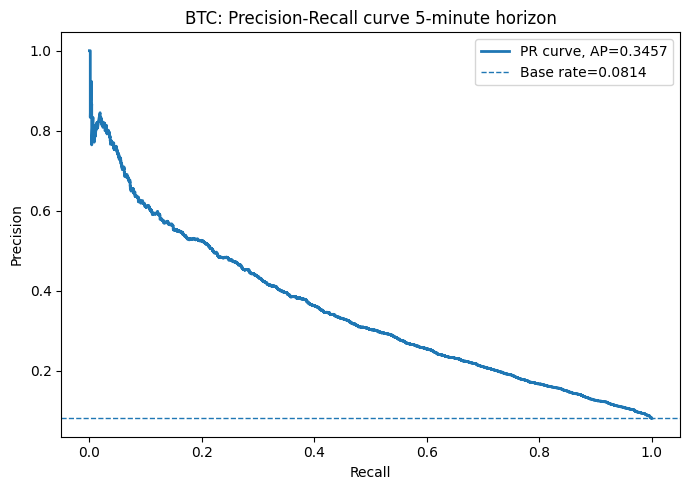

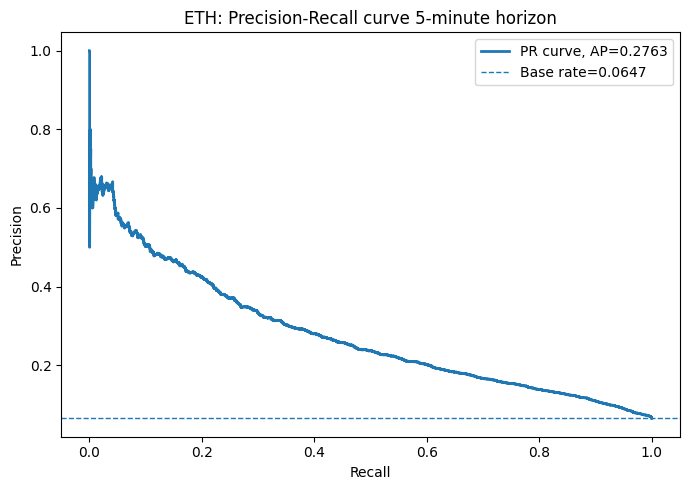

In [31]:
# train classification btc.
clf_btc, Xc_train_btc, Xc_test_btc, yc_train_btc, yc_test_btc, proba_btc, thr_btc = train_future_liq_classifier(
    df          = df_btc_ml,
    asset_name  = "BTC",
    horizon     = 5,
    quantile    = 0.95
)

# train classification eth.
clf_eth, Xc_train_eth, Xc_test_eth, yc_train_eth, yc_test_eth, proba_eth, thr_eth = train_future_liq_classifier(
    df          = df_eth_ml,
    asset_name  = "ETH",
    horizon     = 5,
    quantile    = 0.95
)

# plot threshhold results.
thr_btc_report = threshold_report(yc_test_btc, proba_btc, "BTC")
thr_eth_report = threshold_report(yc_test_eth, proba_eth, "ETH")

# pr curve for btc.
plot_precision_recall_curve(
    y_true          = yc_test_btc,
    proba           = proba_btc,
    asset_name      = "BTC",
    title_suffix    = "5-minute horizon",
)

# pr curve for eth.
plot_precision_recall_curve(
    y_true          = yc_test_eth,
    proba           = proba_eth,
    asset_name      = "ETH",
    title_suffix    = "5-minute horizon",
)

### <b>Results: classification.</b> 

Since large liquidation events are rare, the default probability threshold \(0.5\) is too conservative. At this threshold, the model has relatively high precision but very low recall. Therefore, we evaluate several probability thresholds.

For BTC, a threshold around \(0.20\) gives a good precision-recall trade-off:

$
precision = 0.314,
\qquad
recall = 0.475,
\qquad
F1 = 0.378.
$

This means that the model flags about \(12.3\%\) of minutes as high-risk and captures about \(47.5\%\) of future large liquidation events.

For ETH, a threshold around \(0.20\) also gives a reasonable balance:

$
precision = 0.300,
\qquad
recall = 0.354,
\qquad
F1 = 0.325.
$

This means that the model flags about \(7.6\%\) of minutes as high-risk and captures about \(35.4\%\) of future large liquidation events.

We need to look at the PR curve, as it can be affected by class imbalance.

The PR curves and threshold tables show that the model is useful mainly as an early-warning ranking system. It does not perfectly classify all future liquidation events, but it assigns higher risk scores to periods where large future liquidations are more likely.

The threshold can be selected depending on the goal:
- lower threshold: higher recall, more early warnings;
- higher threshold: higher precision, fewer but more reliable alerts.

Overall, the classifier should be interpreted as a liquidation-risk ranking model rather than a hard binary classifier with a fixed \(0.5\) threshold.